# FNEWS EDA — Image EDA

Image measurements come from exact processed bytes. Pixel distributions are potential artifact signals, not semantic image understanding.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
while not (ROOT / 'reports' / 'EDA').exists(): ROOT = ROOT.parent
EDA = ROOT / 'reports' / 'EDA'
FIG = EDA / 'figures'
summary = json.loads((EDA / 'eda_summary.json').read_text())
summary

{'verified_pairs': 4233,
 'splits': [{'dataset': 'Fakeddit research-v1',
   'split': 'train',
   'manifest_rows': 1185253,
   'verified_pairs': 2353,
   'text_available': 2353,
   'image_available': 2353,
   'raw_label_1_source_true': 1199,
   'raw_label_0_source_non_true': 1154},
  {'dataset': 'Fakeddit research-v1',
   'split': 'validate',
   'manifest_rows': 124425,
   'verified_pairs': 933,
   'text_available': 933,
   'image_available': 933,
   'raw_label_1_source_true': 377,
   'raw_label_0_source_non_true': 556},
  {'dataset': 'Fakeddit research-v1',
   'split': 'test',
   'manifest_rows': 125115,
   'verified_pairs': 947,
   'text_available': 947,
   'image_available': 947,
   'raw_label_1_source_true': 382,
   'raw_label_0_source_non_true': 565}],
 'readable_images': 4233,
 'corrupt_images': 0,
 'exact_text_cross_split_groups': 19,
 'exact_image_cross_split_groups': 0}

width                                                    \
                  count    mean    std    min    25%    50%    75%    max   
source_label                                                                
SOURCE_NON_TRUE  2275.0  390.33  96.72  108.0  320.0  320.0  512.0  512.0   
SOURCE_TRUE      1958.0  314.85  23.54  108.0  320.0  320.0  320.0  320.0   

                 height          ... aspect         bytes                      \
                  count    mean  ...    75%   max   count      mean       std   
source_label                     ...                                            
SOURCE_NON_TRUE  2275.0  345.28  ...   1.53  4.71  2275.0  34900.01  19329.31   
SOURCE_TRUE      1958.0  293.45  ...   1.70  8.00  1958.0  21753.35  11220.39   

                                                               
                    min      25%      50%       75%       max  
source_label                                                   
SOURCE_NON_TRUE  1551.0  19593.0  32443.0  47491.00  152273.0  
SOURCE_TRUE      1638.0  13779.5  19118.0  27141.25   83447.0  

[2 rows x 48 columns]

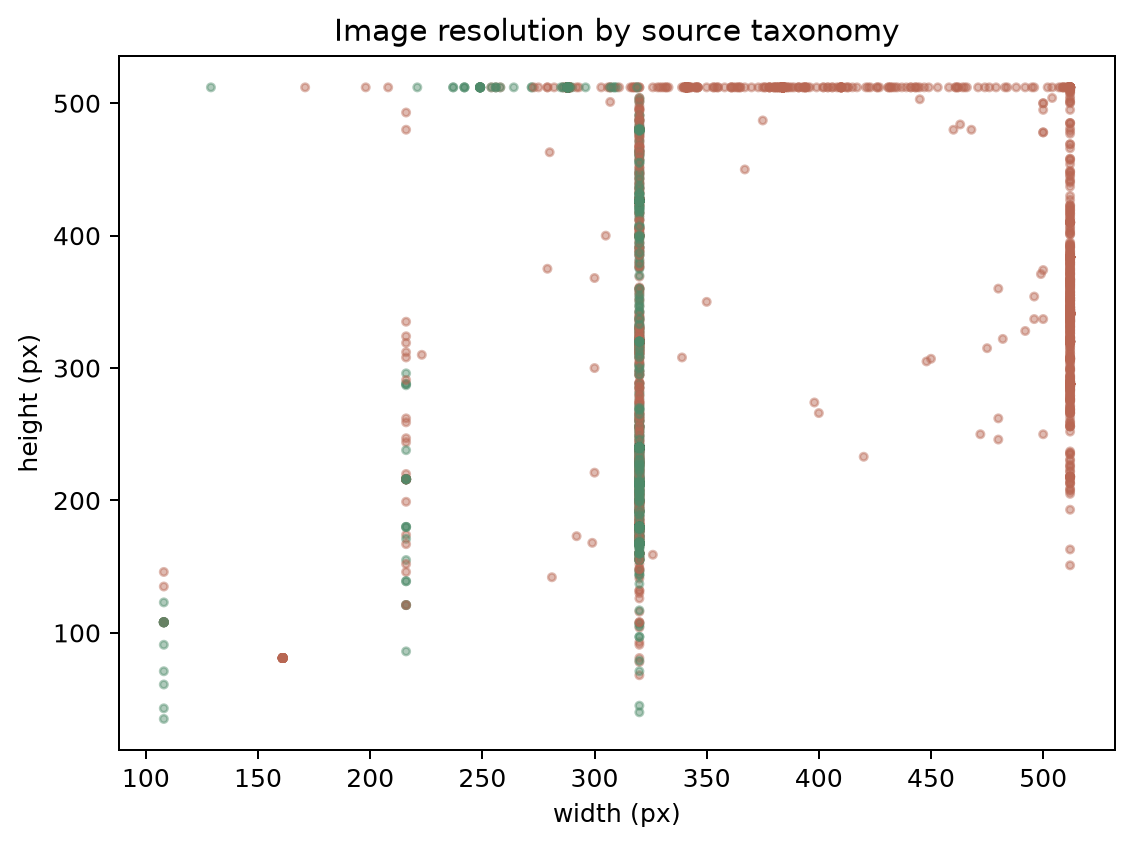

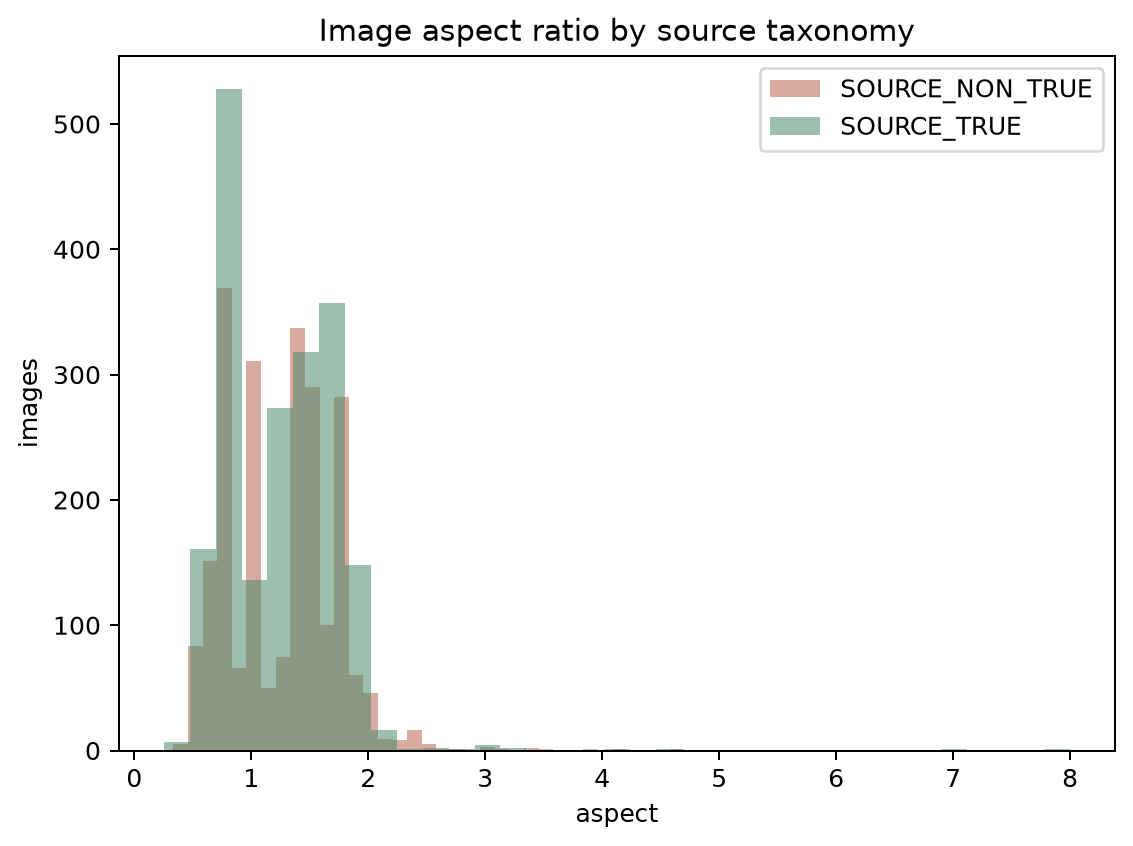

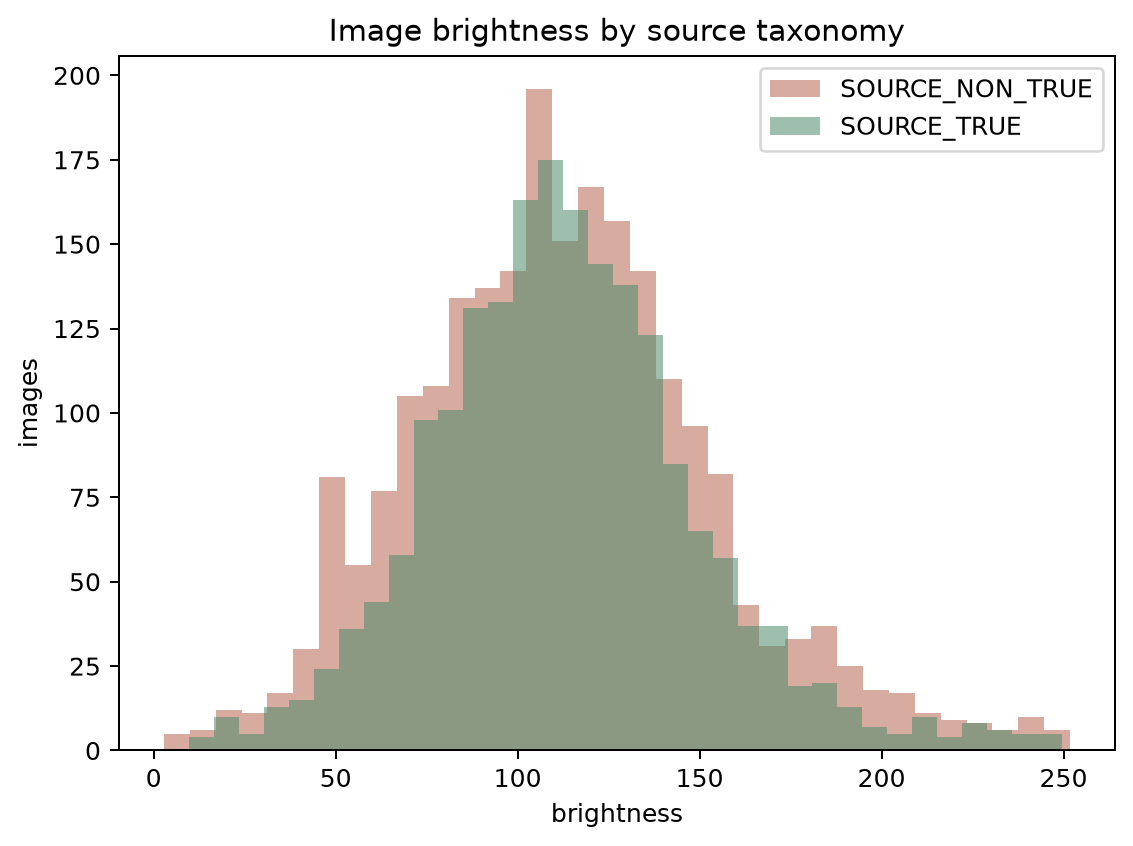

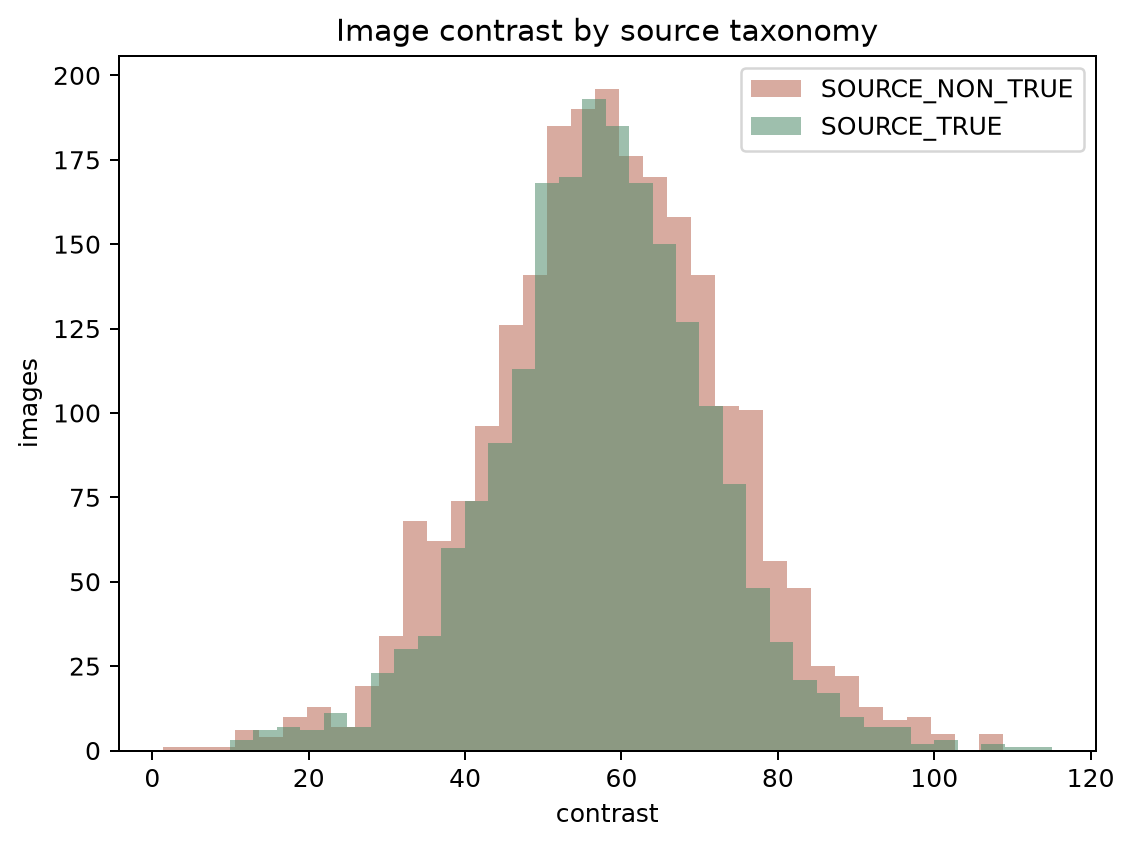

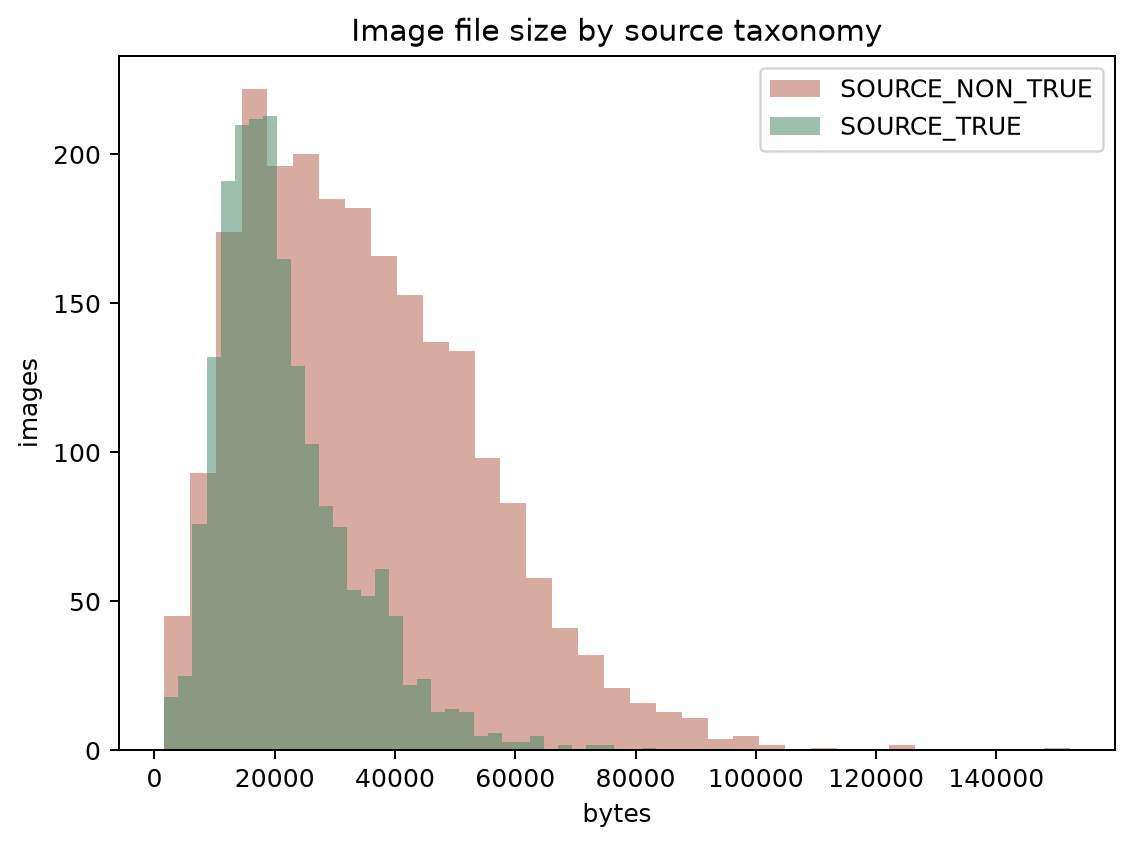

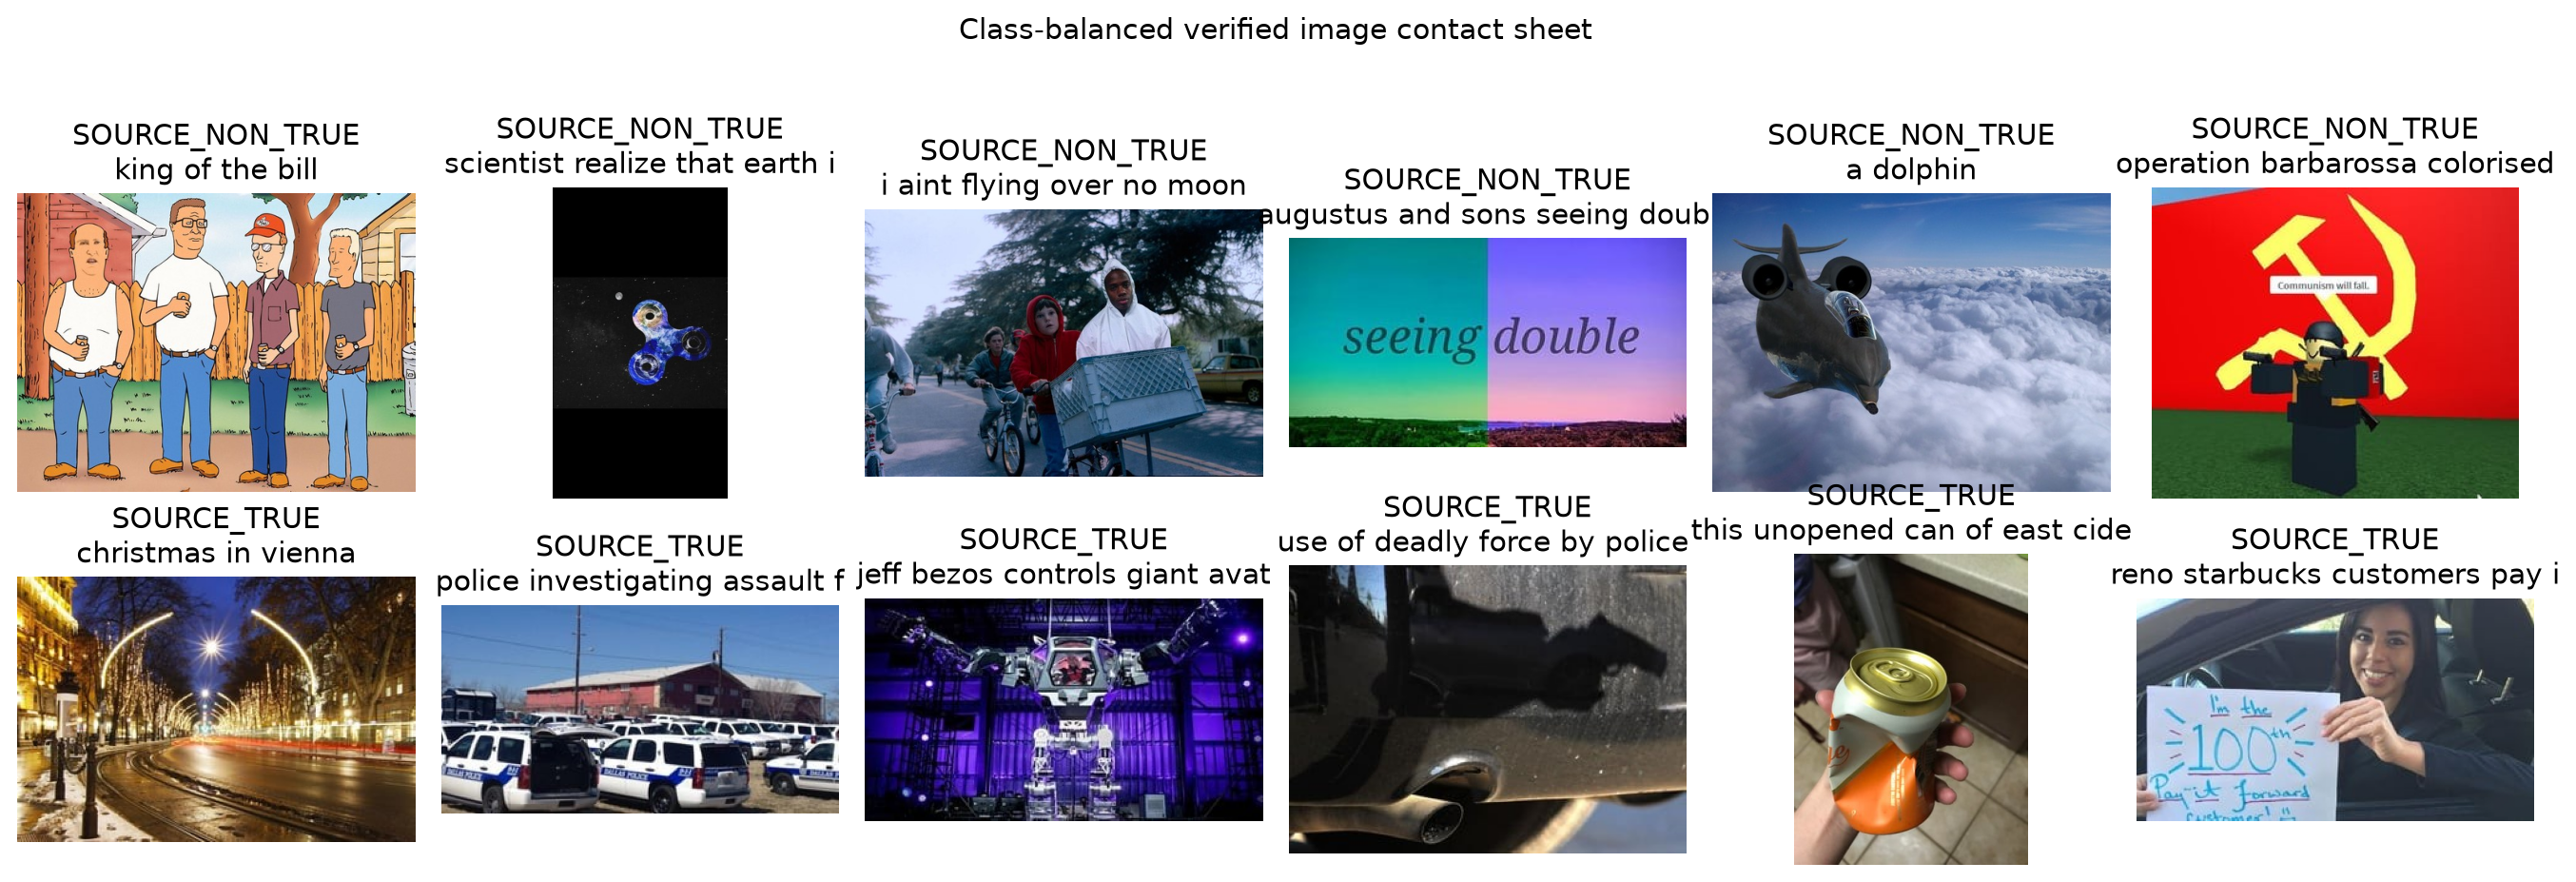

In [2]:
images=pd.read_csv(EDA/'tables'/'image_features.csv')
display(images.groupby('source_label')[['width','height','brightness','contrast','aspect','bytes']].describe().round(2))
for n in ['12_resolution_scatter.png','13_aspect.png','14_brightness.png','15_contrast.png','16_bytes.png','20_contact_sheet.png']: display(Image(filename=str(FIG/n)))

### Reproducibility note

Generated from local manifests and processed images by `scripts/run_comprehensive_eda.py`. No external content was fetched and no model training occurred.